# Assignment 9

## Exercise 1


Consider the computational domain $\Omega \subset \mathbb{R}^2$ shown in the figure.

The elastostatic problem to be solved on this domain reads:

$$
\left\{
\begin{aligned}
\boldsymbol{\sigma}
&= \lambda (\nabla \cdot \boldsymbol{u})\boldsymbol{I}
+ \mu\left(\nabla \boldsymbol{u} + \nabla \boldsymbol{u}^{\mathsf{T}}\right),
\\[1em]
-\nabla \cdot \boldsymbol{\sigma}
&= \boldsymbol{f} \quad \text{in } \Omega,
\\[1em]
\boldsymbol{u}
&= \boldsymbol{u}_{\mathrm{bottom}}
\quad \text{in } \Gamma_{\mathrm{bottom}}
= \left\{(x_1,x_2)\in\partial\Omega,\ x_2=0\right\},
\\[1em]
\boldsymbol{u}
&= \boldsymbol{u}_{\mathrm{top}}
\quad \text{in } \Gamma_{\mathrm{top}}
= \left\{(x_1,x_2)\in\partial\Omega,\ x_2=H\right\},
\\[1em]
\boldsymbol{\sigma}\cdot\check{\boldsymbol{n}}
&= \boldsymbol{\mathcal{F}}
\quad \text{in } \Gamma_N
= \partial\Omega \setminus
\left(\Gamma_{\mathrm{bottom}}\cup\Gamma_{\mathrm{top}}\right).
\end{aligned}
\right.
$$

where

$$
\mu = \frac{E}{2(1+\nu)},
\qquad
\lambda = \frac{E\nu}{(1+\nu)(1-2\nu)}.
$$

and

- $E=10$ (Young's modulus), $\nu=0.3$ (Poisson's ratio).
- $\boldsymbol{f}=(0,0)^{\mathsf{T}}$.
- $\boldsymbol{\mathcal{F}}=(0,0)^{\mathsf{T}}$.
- $\boldsymbol{u}_{\mathrm{bottom}}=(0,0)^{\mathsf{T}}$.
- $\boldsymbol{u}_{\mathrm{top}}=(0,0.1)^{\mathsf{T}}$.

**Write the continuous variational formulation. Define the linear and bilinear forms and the trial and test spaces to be considered.**


By the principle of virtual work, we have:

$$
\underbrace{\int_\Omega (2\mu \varepsilon (\boldsymbol{u}) : \varepsilon (\boldsymbol{v}) +
\lambda (\nabla \cdot \boldsymbol{u}) (\nabla \cdot \boldsymbol{v})) dx}_{a(\mathbf{u},\mathbf{v})} = 
\underbrace{\int_\Omega \boldsymbol{f} \cdot \boldsymbol{v} dx + \int_{\Gamma_N} 
\boldsymbol{\mathcal{F}} \cdot \boldsymbol{v} ds}_{l(\boldsymbol{v})}
$$


Here, $\boldsymbol{v} \in V_{D0} = \{\boldsymbol{v} \in [H^1(\Omega)]^2 \mid \boldsymbol{v} = 0 \text{ in } \Gamma_D \}$ and
$\boldsymbol{u} \in V_{Dg} = \{\boldsymbol{v} \in [H^1(\Omega)]^2 \mid \boldsymbol{v} = \boldsymbol{u}_{bottom} \text{ in } \Gamma_{bottom} \text{ and } \boldsymbol{v} = \boldsymbol{u}_{top} \text{ in } \Gamma_{top} \}$

Therefore, we can write the variational problem:

Find $\boldsymbol{u} \in V_{Dg}$ such that $a(\boldsymbol{u}, \boldsymbol{v}) = l(\boldsymbol{v})$, $\forall \boldsymbol{v} \in V_{D0}$

## Exercise 2

**Write the discrete variational formulation. Considering continuous $P_1$ elements, define the discrete spaces to be used.**

Let $\mathcal{T}_h$ be a conforming triangulation of $\Omega$. We define the spaces:

- $V_{h0} = \{ \boldsymbol{v} \in V_{D0} \mid v\restriction_K \in P_1(K); K \in \mathcal{T}_h \}$
- $V_{hg} = \{ \boldsymbol{v} \in V_{Dg} \mid v\restriction_K \in P_1(K); K \in \mathcal{T}_h \}$

The discrete variational formulation is:

Find $\boldsymbol{u}_h \in V_{hg}$ such that $a(\boldsymbol{u}_h, \boldsymbol{v}_h) = l(\boldsymbol{v}_h)$, $\forall \boldsymbol{v}_h \in V_{h0}$

## Exercise 3
**Implement a Firedrake script to solve the problem above. To that end, construct a 2D finite element triangulation of the domain as shown in the figure. Notice that we need to declare now a space of vector-valued functions**

```python
    V = fd.VectorFunctionSpace(msh, ’CG’, degree=1)
```

firedrake:WARNING OMP_NUM_THREADS is not set or is set to a value greater than 1, we suggest setting OMP_NUM_THREADS=1 to improve performance
PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 20%] Meshing curve 2 (Line)
Info    : [ 30%] Meshing curve 3 (Circle)
Info    : [ 40%] Meshing curve 4 (Circle)
Info    : [ 60%] Meshing curve 5 (Line)
Info    : [ 70%] Meshing curve 6 (Line)
Info    : [ 80%] Meshing curve 7 (Line)
Info    : [ 90%] Meshing curve 8 (Line)
Info    : Done meshing 1D (Wall 0.0227681s, CPU 0.02048s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.0653969s, CPU 0.059922s)
Info    : 1875 nodes 3755 elements
Info    : Writing 'corpo.msh'...
Info    : Done writing 'corpo.msh'


/tmp/ipykernel_103736/1558396175.py:159: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


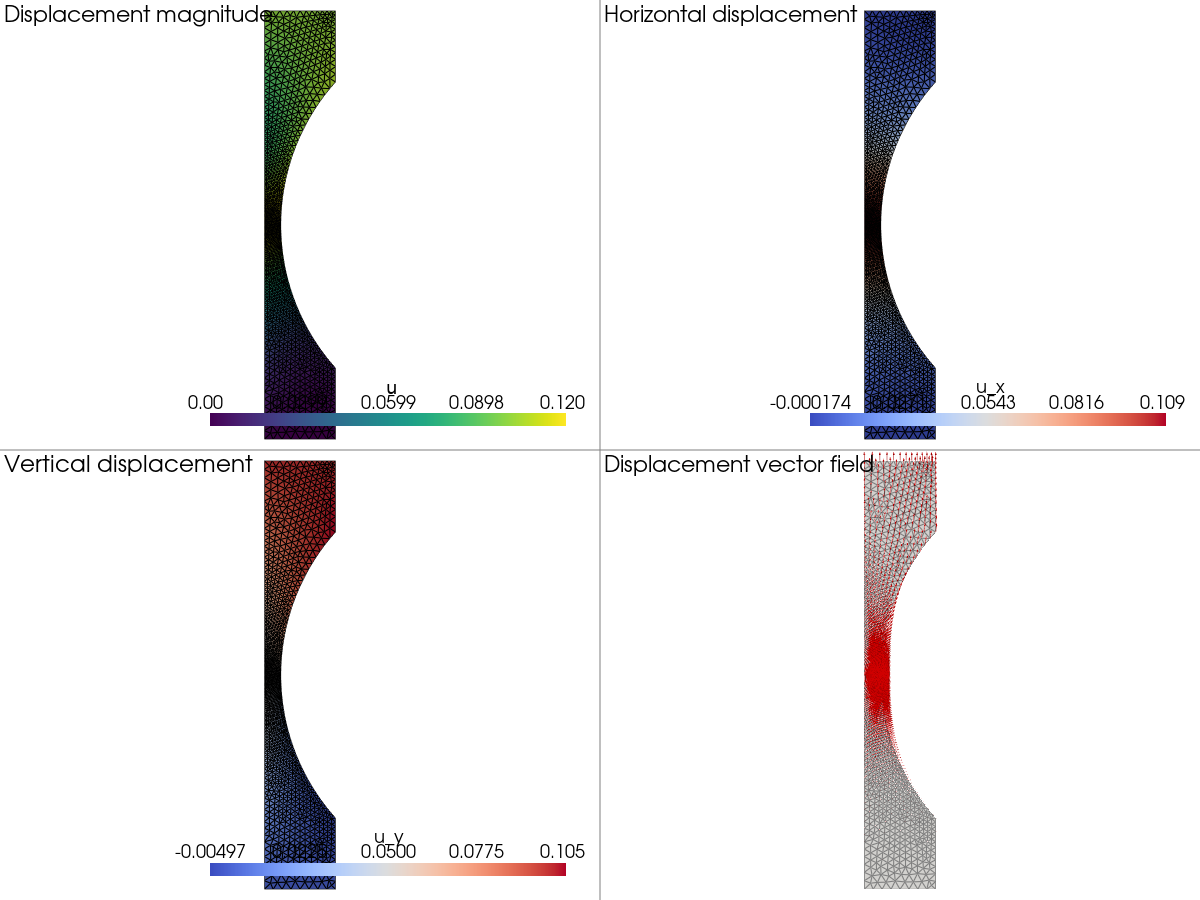

In [1]:
import gmsh
import numpy as np
import firedrake as fd
from firedrake.output import VTKFile
import pyvista as pv

def CreateMeshBody():

    gmsh.initialize()

    lc = 0.05
    
    Db   = 0.4
    Hb   = 0.4
    Hp   = 6*Hb
    R    = 3*Hb
    TT   = np.sqrt(R*R - 4*Hb*Hb)
    
    gmsh.model.occ.addPoint(0, 0, 0, lc, 1)
    gmsh.model.occ.addPoint(Db, 0, 0, lc, 2)
    gmsh.model.occ.addPoint(Db, Hb, 0, 0.5*lc, 3)
    gmsh.model.occ.addPoint(TT+Db, 3*Hb, 0, lc, 4)
    gmsh.model.occ.addPoint(Db, 5*Hb, 0, lc, 5)
    gmsh.model.occ.addPoint(Db, 6*Hb, 0, 0.5*lc, 6)
    gmsh.model.occ.addPoint(0, 6*Hb, 0, lc, 7)
    gmsh.model.occ.addPoint(0, 3*Hb, 0, 0.1*lc, 8)
    gmsh.model.occ.addPoint(TT+Db-R, 3*Hb, 0, 0.1*lc, 9)
    
    gmsh.model.occ.addLine(1, 2, 1)
    gmsh.model.occ.addLine(2, 3, 2)

    gmsh.model.occ.addCircleArc(3, 4, 9, 3)
    gmsh.model.occ.addCircleArc(9, 4, 5, 4)
    
    gmsh.model.occ.addLine(5, 6, 5)
    gmsh.model.occ.addLine(6, 7, 6)
    gmsh.model.occ.addLine(7, 8, 7)
    gmsh.model.occ.addLine(8, 1, 8)
    gmsh.model.occ.synchronize()

    bottomwall, topwall = [], []
    for line in gmsh.model.getEntities(dim=1):
        com = gmsh.model.occ.getCenterOfMass(line[0], line[1])
        if np.isclose(com[1], 0):
            bottomwall.append(line[1])
        if np.isclose(com[1], 6*Hb):
            topwall.append(line[1])
    
    gmsh.model.addPhysicalGroup(1, bottomwall, 200)
    gmsh.model.addPhysicalGroup(1, topwall, 300)
    
    gmsh.model.occ.addCurveLoop([1, 2, 3, 4, 5, 6, 7, 8], 1)
    gmsh.model.occ.addPlaneSurface([1], 1)
    gmsh.model.occ.synchronize()
    gmsh.model.addPhysicalGroup(1, [1, 2, 3, 4, 5, 6, 7, 8], 101)
    ps = gmsh.model.addPhysicalGroup(2, [1])
    gmsh.model.setPhysicalName(2, ps, "My surface") 
    gmsh.model.occ.synchronize()
    gmsh.option.setNumber("Mesh.Algorithm", 6)
    gmsh.model.mesh.generate(2)

    gmsh.write("corpo.msh")
    gmsh.finalize()

    tags = {'bottom': 200, 'top': 300}

    mesh = fd.Mesh("corpo.msh")

    return mesh, tags


def epsilon(v):
    return fd.Constant(0.5) * (fd.grad(v) + fd.grad(v).T)




def solve(mesh, Vh, bcs, save_name, plot):
    u, v = fd.TrialFunction(Vh), fd.TestFunction(Vh)

    a = (2.0 * mu * fd.inner(epsilon(u), epsilon(v)) + lamb * fd.div(u) * fd.div(v)) * fd.dx
    L = fd.inner(f, v) * fd.dx


    uh = fd.Function(Vh, name="u")

    opts={"ksp_type": "preonly", "pc_type": "lu"}
    fd.solve(a == L, uh, bcs=bcs, solver_parameters=opts)

    VTKFile(save_name).write(uh)



    if plot:
        grid = pv.read(save_name)
        grid = grid.combine(merge_points=True)

        # Displacement components
        u = grid.point_data["u"]

        grid.point_data["Magnitude"] = np.linalg.norm(u, axis=1)
        grid.point_data["u_x"] = u[:, 0]
        grid.point_data["u_y"] = u[:, 1]

        # Vector glyphs
        arrows = grid.glyph(
            orient="u",
            scale="u",
            factor=0.5
        )

        # Create a 2x2 subplot
        plotter = pv.Plotter(shape=(2, 2), window_size=(1200, 900))

        # 1. Displacement magnitude
        plotter.subplot(0, 0)
        plotter.add_mesh(
            grid,
            scalars="Magnitude",
            cmap="viridis",
            show_edges=True,
            scalar_bar_args={"title": "|u|"}
        )
        plotter.add_text("Displacement magnitude", font_size=12)
        plotter.view_xy()

        # 2. x-component
        plotter.subplot(0, 1)
        plotter.add_mesh(
            grid,
            scalars="u_x",
            cmap="coolwarm",
            show_edges=True,
            scalar_bar_args={"title": "u_x"}
        )
        plotter.add_text("Horizontal displacement", font_size=12)
        plotter.view_xy()

        # 3. y-component
        plotter.subplot(1, 0)
        plotter.add_mesh(
            grid,
            scalars="u_y",
            cmap="coolwarm",
            show_edges=True,
            scalar_bar_args={"title": "u_y"}
        )
        plotter.add_text("Vertical displacement", font_size=12)
        plotter.view_xy()

        # 4. Vector field
        plotter.subplot(1, 1)
        plotter.add_mesh(grid, color="lightgray", opacity=0.5, show_edges=True)
        plotter.add_mesh(arrows, color="red")
        plotter.add_text("Displacement vector field", font_size=12)
        plotter.view_xy()

        plotter.link_views()
        plotter.show()
    return uh


mesh, tags = CreateMeshBody()
VTKFile("mesh.pvd").write(mesh)

E = 10.0
nu = 0.3

mu = fd.Constant(E / (2.0*(1.0 + nu)))
lamb = fd.Constant(E* nu / ((1.0 + nu) * (1.0 - 2.0 * nu)))

f = fd.Constant((0.0,0.0))

u_bottom = fd.as_vector([0.0, 0.0])
u_top = fd.as_vector([0.0, 0.1])

Vh = fd.VectorFunctionSpace(mesh, 'CG', degree=1, dim=2)
bcs = [
        fd.DirichletBC(Vh, u_bottom, tags['bottom']),
        fd.DirichletBC(Vh, u_top, tags['top'])
]

uh = solve(mesh, Vh, bcs, "Solutions/ex_3.pvd", True)


## Exercise 4

**Given the deviatoric stresses**

$$
    \boldsymbol{s} = \boldsymbol{\sigma} - \frac{tr(\boldsymbol{\sigma}) \boldsymbol{I}}{3}
$$

**Compute the scalar quantity known as the Von Mises stress defined as the second invariant of the deviatoric stresses:**

$$
    \sigma_V = \sqrt{\frac{3}{2}\boldsymbol{s} : \boldsymbol{s}}
$$

**For visualization of results, project $\sigma_V$ onto a space of element-wise constant functions**

/tmp/ipykernel_103736/1025908494.py:26: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


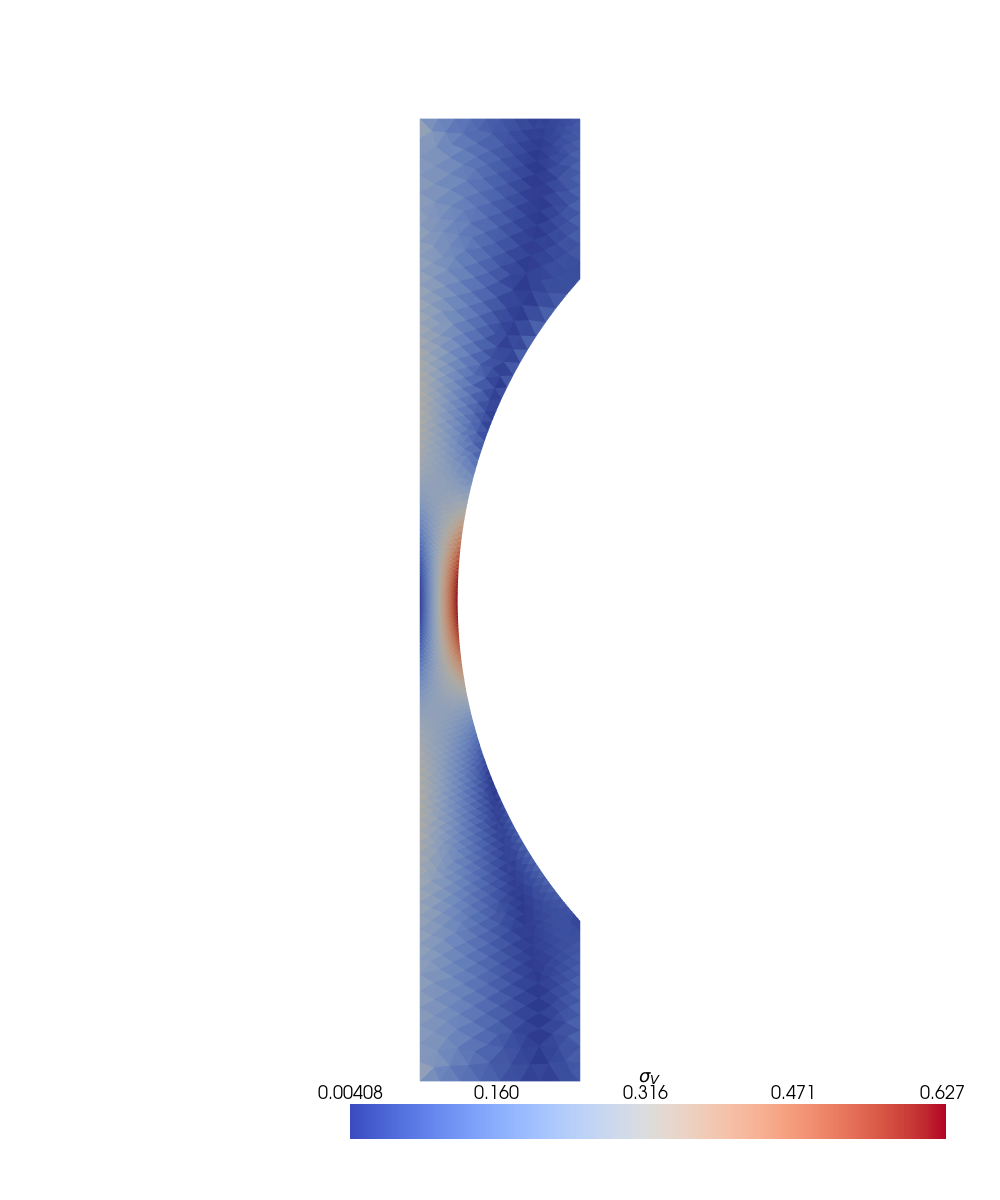

In [2]:
def get_sigmaV(V, uh, mu, lamb, save_name, plot, dim=2):
    sigmah = lamb * fd.div(uh) * fd.Identity(dim) + mu * (epsilon(uh))
    s = sigmah - (fd.tr(sigmah) * fd.Identity(dim)) / 3.0

    sigmaV = fd.Function(V, name="sigmaV")

    sigmaV.interpolate(fd.sqrt((3.0/2.0) * fd.inner(s, s)))

    VTKFile(save_name).write(sigmaV)

    gridV = pv.read(save_name)


    if plot:
        plotter = pv.Plotter(window_size=(1000, 1200))

        plotter.add_mesh(
            gridV,
            scalars="sigmaV",
            cmap="coolwarm",
            show_edges=False,
            scalar_bar_args={"title": r"$\sigma_V$"}
        )
        plotter.view_xy()

        plotter.show()
    return sigmaV

V = fd.FunctionSpace(mesh, 'DG', degree=0)

sigmaV = get_sigmaV(V, uh, mu, lamb, "Solutions/sigma_V.pvd", True)

## Exercise 5

**Repeat the previous points but now assuming the only component to be specified on $\Gamma_{top}$ is the vertical one, meaning that $\boldsymbol{u}_1$ is free (no restrictions) and $\boldsymbol{u}_2 = 0.1$. This can be done by adding the suffix sub(k) to V as follows:**

```python
    bcy = fd.DirichletBC(V.sub(1), fd.Constant(0.1), tag_top)
```

/tmp/ipykernel_103736/1558396175.py:159: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


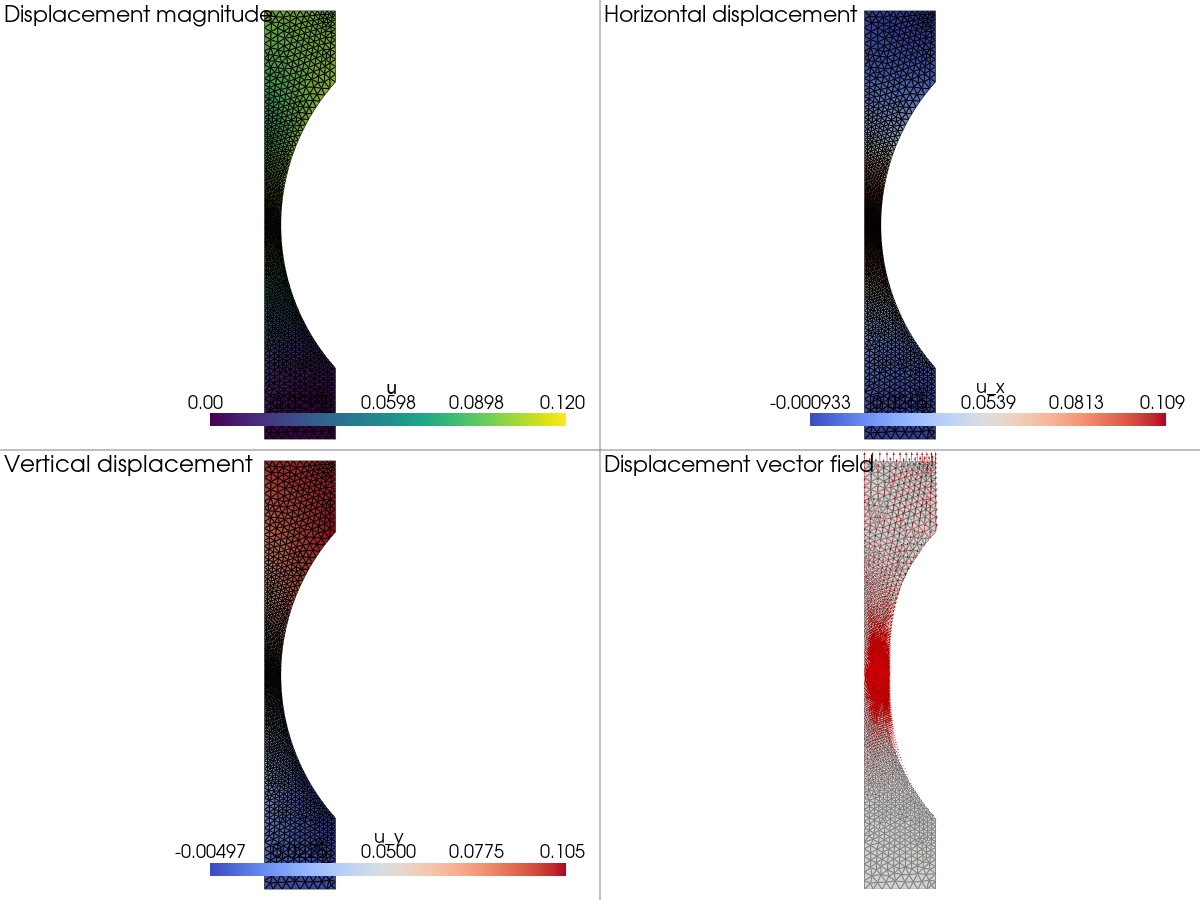

/tmp/ipykernel_103736/1025908494.py:26: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


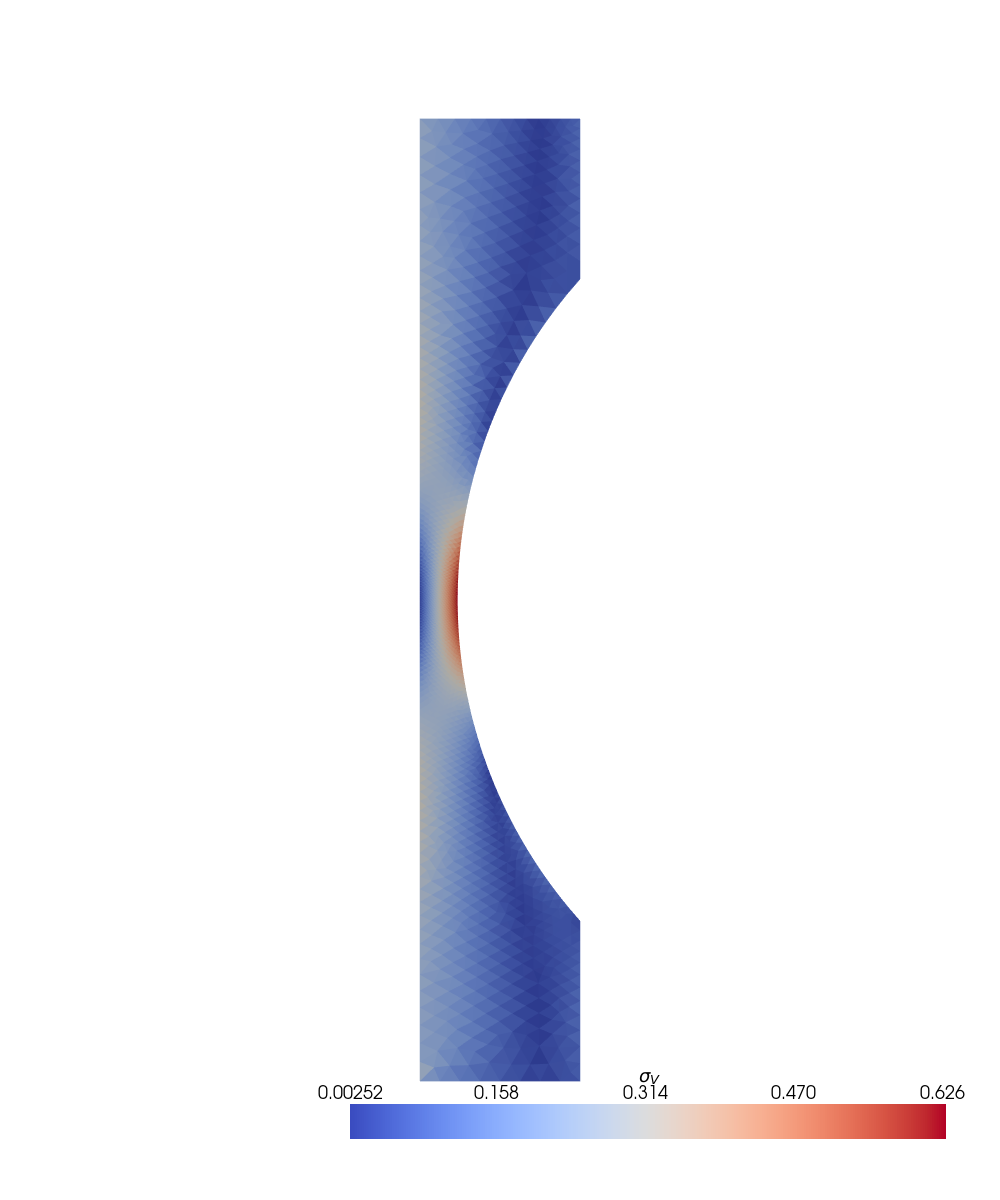

Difference in norm L2 of uh 0.0001530602011558698
Difference in norm L2 of sigmaV 0.0025078942799745723


In [3]:
bcs_ex_5 = [
    fd.DirichletBC(Vh, u_bottom, tags['bottom']),
    fd.DirichletBC(Vh.sub(1), fd.Constant(0.1), tags['top'])
]

uh2 = solve(mesh, Vh,bcs_ex_5, "Solutions/ex_5.pvd", True)
sigmaV2 = get_sigmaV(V, uh2, mu, lamb, "Solutions/sigmaV_ex_5.pvd", True)

diff = fd.Function(Vh, name="diff")
diff.interpolate(uh - uh2)

VTKFile("Solutions/diff.pvd").write(diff)

print("Difference in norm L2 of uh", fd.errornorm(uh, uh2, norm_type="L2"))
print("Difference in norm L2 of sigmaV", fd.errornorm(sigmaV, sigmaV2, norm_type="L2"))

![Difference between the solution](imgs/difference.png)

The solutions are very close, and vary mainly close to the top boundary. The effects through out the body are insignificant. By not setting a BC at the top boundary, we are basically setting a homogeneous Neumann BC for the x-axis component..

## Exercise 6

Implement the 3D version of the previous problem. The geometry is shown in the figure. Consider the following data:

- $E=10$ (Young's modulus), $\nu=0.3$ (Poisson's ratio)
- $\mathbf{f}=(0,0,0)^{\mathsf{T}}$
- $\boldsymbol{\mathcal{F}}=(0,0,0)^{\mathsf{T}}$
- $\mathbf{u}_{\mathrm{bottom}}=(0,0,0)^{\mathsf{T}}$
- $\mathbf{u}_{\mathrm{top}}=(0,0.1,0)^{\mathsf{T}}$

We create the 3D mesh by revolution of the profile shape.

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 20%] Meshing curve 3 (Circle)
Info    : [ 30%] Meshing curve 4 (Circle)
Info    : [ 40%] Meshing curve 5 (Line)
Info    : [ 40%] Meshing curve 6 (Line)
Info    : [ 50%] Meshing curve 7 (Line)
Info    : [ 60%] Meshing curve 8 (Line)
Info    : [ 70%] Meshing curve 9 (Circle)
Info    : [ 70%] Meshing curve 10 (Circle)
Info    : [ 80%] Meshing curve 11 (Circle)
Info    : [ 90%] Meshing curve 12 (Circle)
Info    : [100%] Meshing curve 13 (Circle)
Info    : Done meshing 1D (Wall 0.0122856s, CPU 0.013s)
Info    : Meshing 2D...
Info    : [  0%] Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : [ 20%] Meshing surface 2 (Plane, Frontal-Delaunay)
Info    : [ 30%] Meshing surface 3 (Cylinder, Frontal-Delaunay)
Info    : [ 50%] Meshing surface 4 (Torus, Frontal-Delaunay)


PETSc Error --- Application was linked against both OpenMPI and MPICH based MPI libraries and will not run correctly


Info    : [ 60%] Meshing surface 5 (Torus, Frontal-Delaunay)
Info    : [ 80%] Meshing surface 6 (Cylinder, Frontal-Delaunay)
Info    : [ 90%] Meshing surface 7 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.730242s, CPU 0.710796s)
Info    : Meshing 3D...
Info    : 3D Meshing 1 volume with 1 connected component
Info    : Tetrahedrizing 13664 nodes...
Info    : Done tetrahedrizing 13672 nodes (Wall 0.442354s, CPU 0.41368s)
Info    : Reconstructing mesh...
Info    :  - Creating surface mesh
Info    :  - Identifying boundary edges
Info    :  - Recovering boundary
Info    : Done reconstructing mesh (Wall 1.28479s, CPU 1.21955s)
Info    : Found volume 1
Info    : It. 0 - 0 nodes created - worst tet radius 20.6423 (nodes removed 0 0)
Info    : It. 500 - 499 nodes created - worst tet radius 3.63889 (nodes removed 0 1)
Info    : It. 1000 - 999 nodes created - worst tet radius 2.94251 (nodes removed 0 1)
Info    : It. 1500 - 1499 nodes created - worst tet radius 2.60796 (nodes remov

/tmp/ipykernel_103736/926275532.py:112: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


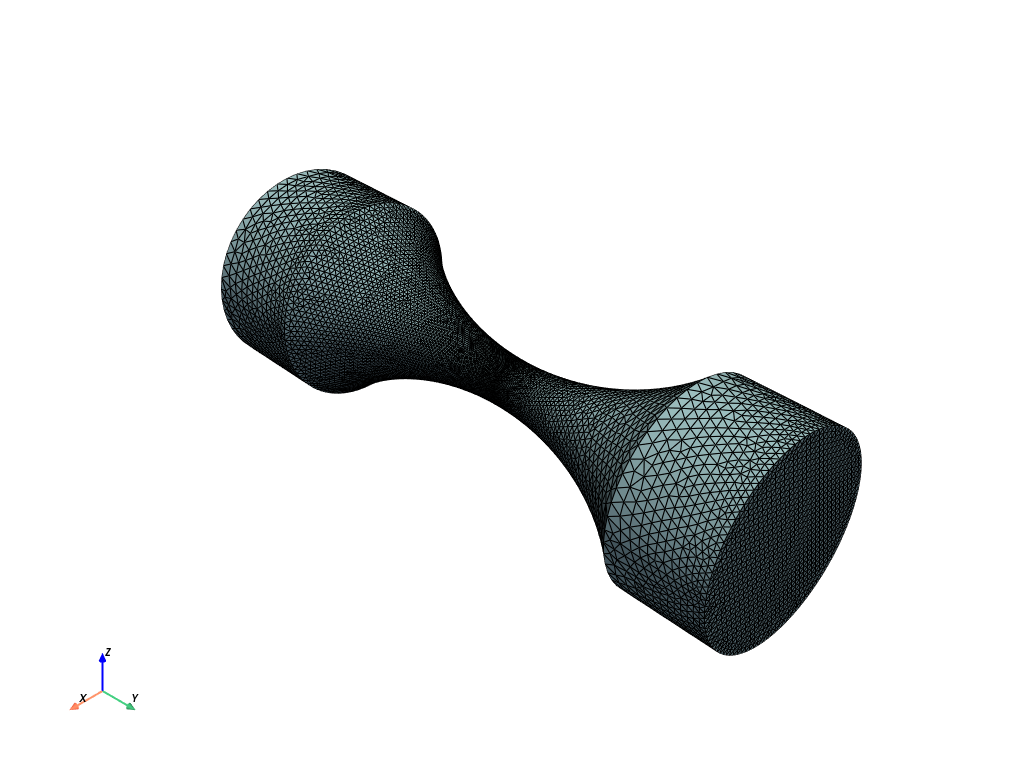

In [4]:
def CreateMeshBody3D():
    gmsh.initialize()
    gmsh.model.add("Body3D")

    lc = 0.05
    Db = 0.4
    Hb = 0.4
    R = 3 * Hb
    TT = np.sqrt(R**2 - 4 * Hb**2)

    # Original 2D profile in the (r, y)-plane.
    # Here r = x and the axis of revolution is y.

    gmsh.model.occ.addPoint(0, 0, 0, lc, 1)
    gmsh.model.occ.addPoint(Db, 0, 0, lc, 2)
    gmsh.model.occ.addPoint(Db, Hb, 0, 0.5 * lc, 3)
    gmsh.model.occ.addPoint(TT + Db, 3 * Hb, 0, lc, 4)
    gmsh.model.occ.addPoint(Db, 5 * Hb, 0, lc, 5)
    gmsh.model.occ.addPoint(Db, 6 * Hb, 0, 0.5 * lc, 6)
    gmsh.model.occ.addPoint(0, 6 * Hb, 0, lc, 7)
    gmsh.model.occ.addPoint(0, 3 * Hb, 0, 0.1 * lc, 8)
    gmsh.model.occ.addPoint(TT + Db - R, 3 * Hb, 0, 0.1 * lc, 9)

    # Boundary curves
    gmsh.model.occ.addLine(1, 2, 1)
    gmsh.model.occ.addLine(2, 3, 2)

    gmsh.model.occ.addCircleArc(3, 4, 9, 3)
    gmsh.model.occ.addCircleArc(9, 4, 5, 4)

    gmsh.model.occ.addLine(5, 6, 5)
    gmsh.model.occ.addLine(6, 7, 6)
    gmsh.model.occ.addLine(7, 8, 7)
    gmsh.model.occ.addLine(8, 1, 8)

    # Create the closed 2D profile
    loop = gmsh.model.occ.addCurveLoop(
        [1, 2, 3, 4, 5, 6, 7, 8]
    )
    surface = gmsh.model.occ.addPlaneSurface([loop])

    # Revolve the profile around the y-axis through 2*pi.
    result = gmsh.model.occ.revolve(
        [(2, surface)],
        0, 0, 0,          # Point on the axis
        0, 1, 0,          # Axis direction
        2 * np.pi
    )

    gmsh.model.occ.synchronize()

    # Identify the generated volume.
    volumes = [tag for dim, tag in result if dim == 3]

    if len(volumes) != 1:
        gmsh.finalize()
        raise RuntimeError(
            f"Expected one volume, but found {len(volumes)}."
        )

    # Identify the top and bottom boundary surfaces.
    bottomwall, topwall = [], []

    for dim, tag in gmsh.model.getEntities(2):
        com = gmsh.model.occ.getCenterOfMass(dim, tag)

        if np.isclose(com[1], 0.0):
            bottomwall.append(tag)

        if np.isclose(com[1], 6 * Hb):
            topwall.append(tag)

    # Physical surface markers for Firedrake boundary conditions.
    gmsh.model.addPhysicalGroup(2, bottomwall, 200)
    gmsh.model.setPhysicalName(2, 200, "Bottom")

    gmsh.model.addPhysicalGroup(2, topwall, 300)
    gmsh.model.setPhysicalName(2, 300, "Top")

    # Physical volume group is essential for retaining 3D elements.
    gmsh.model.addPhysicalGroup(3, volumes, 1000)
    gmsh.model.setPhysicalName(3, 1000, "Body")

    # Generate a tetrahedral volume mesh.
    gmsh.option.setNumber("Mesh.Algorithm3D", 1)
    gmsh.option.setNumber("Mesh.MeshSizeMin", 0.1 * lc)
    gmsh.option.setNumber("Mesh.MeshSizeMax", lc)

    gmsh.model.mesh.generate(3)

    gmsh.write("corpo3D.msh")
    gmsh.finalize()

    mesh = fd.Mesh("corpo3D.msh")

    tags = {
        "bottom": 200,
        "top": 300
    }

    return mesh, tags


mesh3D, tags3D = CreateMeshBody3D()
VTKFile("mesh3D.pvd").write(mesh3D)

grid = pv.read("mesh3D.pvd").combine(merge_points=True)

plotter = pv.Plotter()
plotter.add_mesh(grid, show_edges=True, color="lightblue")
plotter.add_axes()
plotter.show()

/tmp/ipykernel_103736/1558396175.py:159: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


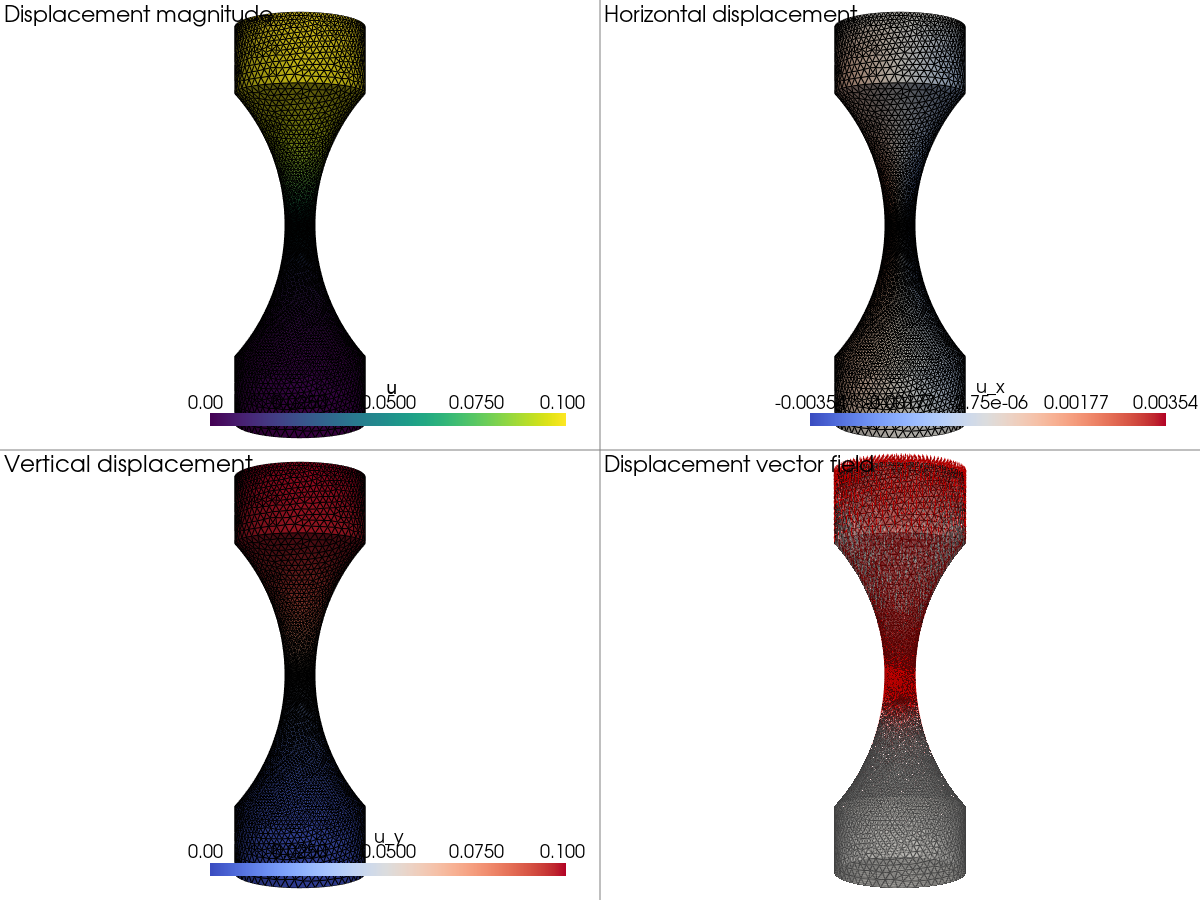

In [6]:
Vh3D = fd.VectorFunctionSpace(mesh3D, 'CG', degree=1, dim=3)

u_bottom3D = fd.as_vector([0.0,0.0,0.0])
u_top3D = fd.as_vector([0.0,0.1,0.0])

f = fd.Constant((0.0,0.0,0.0))


bcs3D = [
    fd.DirichletBC(Vh3D, u_bottom3D, tags3D['bottom']),
    fd.DirichletBC(Vh3D, u_top3D, tags3D['top'])
]

uh3D = solve(mesh3D, Vh3D, bcs3D, "Solutions/ex_6.pvd", True)

/tmp/ipykernel_103736/1025908494.py:26: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


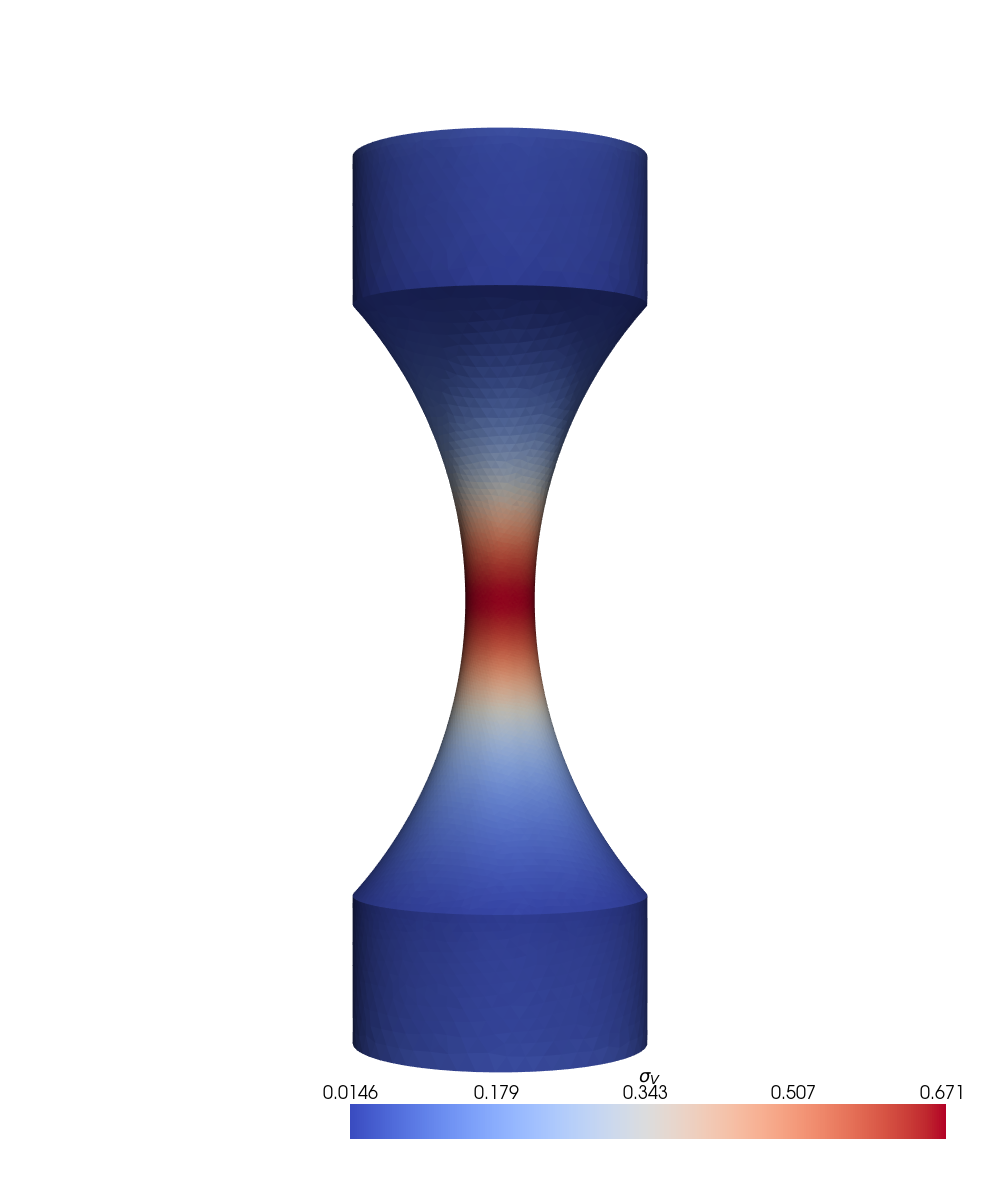

In [8]:
V3D = fd.FunctionSpace(mesh3D, 'DG', degree=0)
sigmaV3D = get_sigmaV(V3D, uh3D, mu, lamb, "Solutions/sigmaV3D.pvd", True, dim=3)